# HIGGS · Random Forest
Member 3 · Progress Evaluation

This notebook uses the team's existing **unscaled** splits. It fits each candidate on train, selects by validation ROC-AUC, and evaluates the selected train-fitted model on test. Candidate ties keep the first configuration in the grid. The test split is read after selection.

Run from the project root, or set `DATA_DIR` to the folder containing the three Parquet files. For Colab, mount Drive using `from google.colab import drive; drive.mount('/content/drive')` and use the actual Drive folder path.

The default uses the **full training split**. If your group agrees to use a fixed training subset for the progress evaluation, set `TRAIN_POSITIONS_FILE` to a shared CSV with a single `row_position` column of zero-based positions in the original training file. Members using scaled data must verify that those same positions identify the same records. Validation and test use their complete splits.

In [4]:
print("Colab is working!")

Colab is working!


In [5]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Uncomment if your notebook environment needs these packages.
# %pip install numpy pandas pyarrow scikit-learn matplotlib joblib

In [9]:
from itertools import product
from pathlib import Path
from time import perf_counter
import hashlib
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, auc,
    confusion_matrix, f1_score, log_loss, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)

DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed")
OUTPUT_DIR = Path("/content/drive/MyDrive/results/random_forest")
TRAIN_POSITIONS_FILE = None  # Example: Path("data/train_positions.csv")
SEED = 42
N_JOBS = 2  # Reduce to 1 if memory is tight.
N_ESTIMATORS = [50]
MAX_DEPTHS = [16]
TARGET = "target"

paths = {split: DATA_DIR / f"{split}.parquet" for split in ("train", "validation", "test")}
missing = [str(path) for path in paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing unscaled files: {', '.join(missing)}")

train_positions = None
subset_sha256 = None
if TRAIN_POSITIONS_FILE is not None:
    positions_file = Path(TRAIN_POSITIONS_FILE)
    positions = pd.read_csv(positions_file, usecols=["row_position"])["row_position"]
    if positions.empty or not pd.api.types.is_integer_dtype(positions):
        raise ValueError("Use a nonempty CSV of integer row positions.")
    train_positions = np.sort(positions.to_numpy(dtype=np.int64))
    total = pq.ParquetFile(paths["train"]).metadata.num_rows
    if train_positions[0] < 0 or train_positions[-1] >= total:
        raise ValueError("Train positions are outside the original train split.")
    if np.unique(train_positions).size != train_positions.size:
        raise ValueError("Train positions must be unique.")
    subset_sha256 = hashlib.sha256(train_positions.astype("<i8").tobytes()).hexdigest()
    print("Dataset files found:", [path.name for path in paths.values()])

In [10]:
def load_split(path, positions=None):
    if positions is None:
        frame = pd.read_parquet(path, engine="pyarrow")
    else:
        parts = []
        offset = 0
        for batch in pq.ParquetFile(path).iter_batches(batch_size=100_000):
            start, end = np.searchsorted(positions, [offset, offset + batch.num_rows])
            if start < end:
                parts.append(batch.take(positions[start:end] - offset).to_pandas())
            offset += batch.num_rows
            if offset > positions[-1]:
                break
        frame = pd.concat(parts, ignore_index=True)

    if TARGET not in frame or frame.shape[1] != 29:
        raise ValueError(f"{path.name} should contain target and 28 feature columns.")
    y = frame.pop(TARGET)
    if y.isna().any() or set(y.unique()) != {0, 1}:
        raise ValueError(f"{path.name} must contain both binary classes and no missing labels.")
    return frame.astype(np.float32, copy=False), y.to_numpy(dtype=np.int8)


X_train, y_train = load_split(paths["train"], train_positions)
X_val, y_val = load_split(paths["validation"])
feature_names = X_train.columns.tolist()
if set(X_val.columns) != set(feature_names):
    raise ValueError("Training and validation feature columns do not match.")
if X_val.columns.tolist() != feature_names:
    X_val = X_val[feature_names]
n_train, n_val = len(y_train), len(y_val)
print(f"Train: {n_train:,}  |  Validation: {n_val:,}")

Train: 7,504,911  |  Validation: 1,608,195


## Tune on validation

Each candidate uses the same training records. Training time measures `fit()` only. Keep the validation winner and record total fit time across all candidates separately. The grid is deliberately small for the progress evaluation.

In [11]:
import numpy as np
from itertools import product

trials = []
best_auc = -np.inf
best_model = None
best_trial = None

for n_estimators, max_depth in product(N_ESTIMATORS, MAX_DEPTHS):
    candidate = RandomForestClassifier(
        n_estimators=n_estimators, max_depth=max_depth,
        random_state=SEED, n_jobs=N_JOBS,
    )
    started = perf_counter()
    candidate.fit(X_train, y_train)
    elapsed = perf_counter() - started
    val_auc = roc_auc_score(y_val, candidate.predict_proba(X_val)[:, 1])
    trial = {
        "n_estimators": n_estimators, "max_depth": max_depth,
        "validation_roc_auc": val_auc, "training_time_seconds": elapsed,
    }
    trials.append(trial)
    print(f"{n_estimators} trees, depth {max_depth}: ROC-AUC {val_auc:.5f}, fit {elapsed:.1f}s")
    if val_auc > best_auc:
        best_auc, best_model, best_trial = val_auc, candidate, trial
    del candidate

tuning_results = pd.DataFrame(trials).sort_values("validation_roc_auc", ascending=False, kind="stable")
del X_train, y_train, X_val, y_val
tuning_results

50 trees, depth 16: ROC-AUC 0.81138, fit 2931.0s


,n_estimators,max_depth,validation_roc_auc,training_time_seconds
0,50,16,0.811383,2930.983919


In [12]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUT_DIR / "random_forest.joblib"
joblib.dump(best_model, model_path, compress=3)
print("Model saved to:", model_path)

Model saved to: /content/drive/MyDrive/results/random_forest/random_forest.joblib


In [13]:
X_test, y_test = load_split(paths["test"])
if set(X_test.columns) != set(feature_names):
    raise ValueError("Training and test feature columns do not match.")
if X_test.columns.tolist() != feature_names:
    X_test = X_test[feature_names]

probability = best_model.predict_proba(X_test)[:, 1]
# Match scikit-learn's binary argmax, including its tie-break toward class 0.
prediction = (probability > 0.5).astype(np.int8)
pr_precision, pr_recall, _ = precision_recall_curve(y_test, probability)
metrics = {
    "model": "Random Forest",
    "accuracy": accuracy_score(y_test, prediction),
    "precision": precision_score(y_test, prediction, zero_division=0),
    "recall": recall_score(y_test, prediction, zero_division=0),
    "f1": f1_score(y_test, prediction, zero_division=0),
    "roc_auc": roc_auc_score(y_test, probability),
    "pr_auc": auc(pr_recall, pr_precision),
    "log_loss": log_loss(y_test, probability, labels=[0, 1]),
    "training_time_seconds": best_trial["training_time_seconds"],
}
pd.DataFrame([metrics])

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,training_time_seconds
0,Random Forest,0.732686,0.741243,0.780962,0.760584,0.811599,0.833651,0.534981,2930.983919


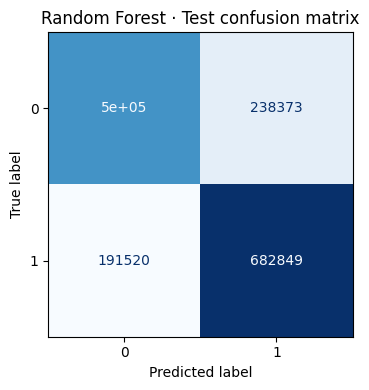

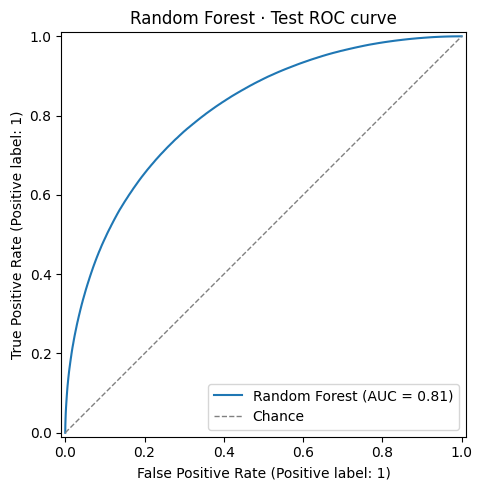

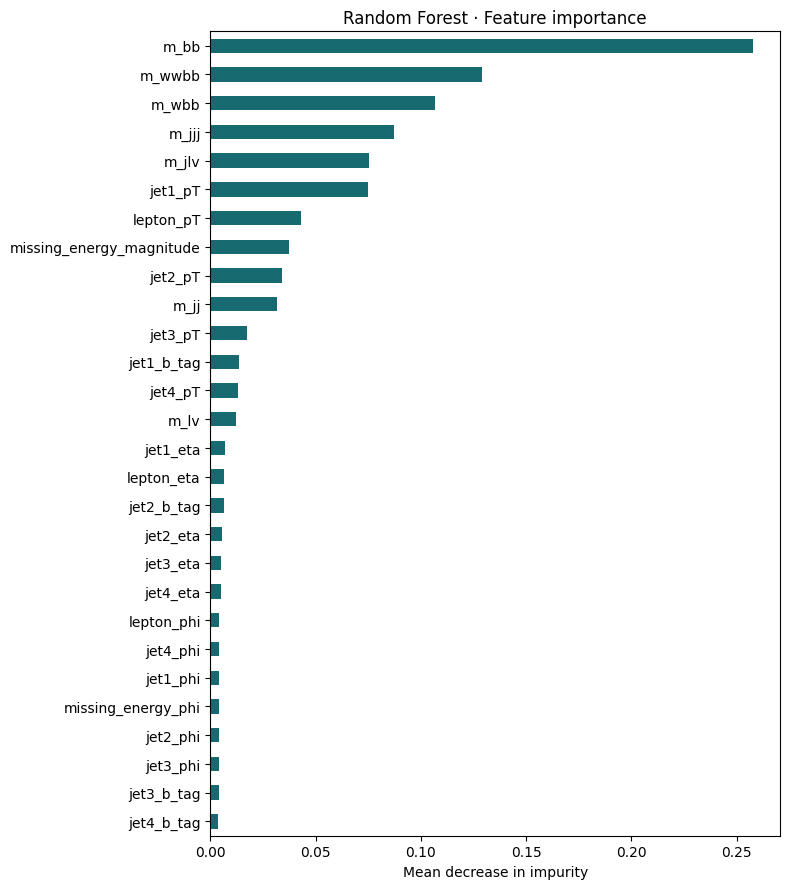

In [14]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
importance = pd.Series(best_model.feature_importances_, index=feature_names, name="importance")
importance = importance.sort_values(ascending=False)
cm = confusion_matrix(y_test, prediction, labels=[0, 1])
figures = []
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Random Forest · Test confusion matrix")
figures.append(("confusion_matrix.png", fig))

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, probability, name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1, label="Chance")
ax.legend(loc="lower right")
ax.set_title("Random Forest · Test ROC curve")
figures.append(("roc_curve.png", fig))

fig, ax = plt.subplots(figsize=(8, 9))
importance.sort_values().plot.barh(ax=ax, color="#176b70")
ax.set(xlabel="Mean decrease in impurity", title="Random Forest · Feature importance")
figures.append(("feature_importance.png", fig))

for filename, fig in figures:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
plt.show()

In [15]:
metadata = {
    **metrics,
    "selected_candidate": best_trial,
    "total_candidate_fit_seconds": sum(trial["training_time_seconds"] for trial in trials),
    "train_records": n_train,
    "validation_records": n_val,
    "test_records": len(y_test),
    "train_positions_sha256": subset_sha256,
    "random_state": SEED,
    "n_jobs": N_JOBS,
    "sklearn_version": sklearn.__version__,
    "pr_auc_definition": "trapezoidal area under the precision-recall curve",
}
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
tuning_results.to_csv(OUTPUT_DIR / "validation_tuning.csv", index=False)
importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index_label="feature")
pd.DataFrame(cm, index=["actual_0", "actual_1"], columns=["predicted_0", "predicted_1"]).to_csv(
    OUTPUT_DIR / "confusion_matrix.csv"
)
(OUTPUT_DIR / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
joblib.dump(best_model, OUTPUT_DIR / "random_forest.joblib", compress=3)
assert (OUTPUT_DIR / "random_forest.joblib").stat().st_size > 0
print(f"Saved results and model in {OUTPUT_DIR.resolve()}")

Saved results and model in /content/drive/MyDrive/results/random_forest


## Handoff and viva

- Give Member 4 `test_metrics.csv`, `run_metadata.json`, and the plots. Training time in the CSV is the selected candidate's fit time. Record the runtime hardware when models run on different machines.
- Precision, recall, and F1 use class 1 as positive. ROC-AUC and trapezoidal PR-AUC use probabilities, and log loss measures the quality of those probabilities. Agree on the PR-AUC definition across members before comparing.
- Random Forest averages class probabilities from trees trained on bootstrap samples. Each split considers a random subset of features. Increasing tree count costs time, and limiting depth can control model complexity.
- Impurity-based feature importance reports how much features reduced splits' impurity across the forest. Correlated features can share importance.
- Demo the validation tuning table, selected parameters, test scores, and three plots. Commit the notebook without Parquet files. Share a large model file separately if needed.